# Modularity on the Karate Club Graph
DSC212: Graph Theory Module

In this notebook I find communities in the Karate Club network using the spectral modularity method (Newman, 2006). I build the modularity matrix, split the graph using the leading eigenvector, and keep splitting until no split helps. After every split I draw the graph and compute four node metrics.

## 1. Imports

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

## 2. Load the graph and build the modularity matrix

In [2]:
G = nx.karate_club_graph()
n = G.number_of_nodes()
m = G.number_of_edges()
print("nodes:", n)
print("edges:", m)

A = nx.to_numpy_array(G, weight=None)
k = A.sum(axis=1)

B = A - np.outer(k, k) / (2 * m)

nodes: 34
edges: 78


Quick checks from the handout: B should be symmetric and B times the all-ones vector should be 0.

In [3]:
print("B symmetric:", np.allclose(B, B.T))

ones = np.ones(n)
print("max of |B @ 1|:", np.abs(B @ ones).max())

B symmetric: True
max of |B @ 1|: 8.881784197001252e-16


## 3. Modularity score

In [4]:
def modularity_two(B, s, m):
    return s @ B @ s / (4 * m)


def modularity_many(B, communities, m):
    total = 0
    for c in communities:
        block = B[np.ix_(c, c)]
        total = total + block.sum()
    return total / (2 * m)

## 4. One split of the whole graph

In [5]:
values, vectors = np.linalg.eigh(B)
lam1 = values[-1]
u1 = vectors[:, -1]
print("largest eigenvalue:", lam1)

s = np.where(u1 > 0, 1, -1)
print("Q for this split:", modularity_two(B, s, m))

group_a = [i for i in range(n) if s[i] == 1]
group_b = [i for i in range(n) if s[i] == -1]
print("group 1:", group_a)
print("group 2:", group_b)

largest eigenvalue: 4.977080225729889
Q for this split: 0.37146614069691
group 1: [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
group 2: [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]


Compare with the real split of the club (stored in the graph as the `club` attribute).

In [6]:
mr_hi = [i for i in range(n) if G.nodes[i]["club"] == "Mr. Hi"]
officer = [i for i in range(n) if G.nodes[i]["club"] == "Officer"]

if 0 not in group_a:
    group_a, group_b = group_b, group_a

wrong = []
for i in group_a:
    if i not in mr_hi:
        wrong.append(i)
for i in group_b:
    if i not in officer:
        wrong.append(i)

print("nodes put in the wrong group:", wrong)
print("correct:", n - len(wrong), "out of", n)

nodes put in the wrong group: [8]
correct: 33 out of 34


## 5. Recursive splitting

For a group of nodes `C`, I take the block of `B` for those nodes and find its leading eigenvalue. If it is bigger than 0 I split by the sign of the eigenvector. If not, the group stays as it is (stopping rule from Theorem 3).

I keep a list `history` that stores the partition after every split, so I can draw and measure each iteration later.

In [7]:
def try_split(nodes):
    nodes = list(nodes)
    if len(nodes) < 2:
        return 0, None, None

    B_C = B[np.ix_(nodes, nodes)]
    vals, vecs = np.linalg.eigh(B_C)
    lam = vals[-1]
    vec = vecs[:, -1]

    if lam <= 1e-8:
        return lam, None, None

    left = []
    right = []
    for idx in range(len(nodes)):
        if vec[idx] > 0:
            left.append(nodes[idx])
        else:
            right.append(nodes[idx])

    if len(left) == 0 or len(right) == 0:
        return lam, None, None

    return lam, left, right

In [8]:
to_check = [list(range(n))]
final = []

history = [[list(range(n))]]
split_info = []

while len(to_check) > 0:
    c = to_check.pop(0)
    lam, left, right = try_split(c)

    if left is None:
        final.append(c)
        print("group of size", len(c), "cannot be split (lambda =", round(lam, 3), ")")
    else:
        to_check.append(left)
        to_check.append(right)
        partition = final + to_check
        history.append(partition)
        split_info.append("split group of size " + str(len(c)))
        print("split group of size", len(c), "into", len(left), "and", len(right), "(lambda =", round(lam, 3), ")")

communities = final
print()
print("number of communities:", len(communities))
for c in communities:
    print(sorted(c))

split group of size 34 into 16 and 18 (lambda = 4.977 )
split group of size 16 into 10 and 6 (lambda = 2.944 )
split group of size 18 into 5 and 13 (lambda = 2.504 )
group of size 10 cannot be split (lambda = 2.571 )
split group of size 6 into 1 and 5 (lambda = 2.148 )
group of size 5 cannot be split (lambda = 1.876 )
group of size 13 cannot be split (lambda = 2.356 )
group of size 1 cannot be split (lambda = 0 )
group of size 5 cannot be split (lambda = 2.147 )

number of communities: 5
[0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
[24, 25, 27, 28, 31]
[8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
[11]
[4, 5, 6, 10, 16]


In [9]:
for i in range(len(history)):
    q = modularity_many(B, history[i], m)
    print("iteration", i, "- communities:", len(history[i]), "- Q =", round(q, 4))

iteration 0 - communities: 1 - Q = -0.0
iteration 1 - communities: 2 - Q = 0.3715
iteration 2 - communities: 3 - Q = 0.3898
iteration 3 - communities: 4 - Q = 0.4081
iteration 4 - communities: 5 - Q = 0.4094


## 6. Draw the graph after each iteration

The layout is made once so the nodes stay in the same place in every picture. Iteration 0 is the whole graph before any split.

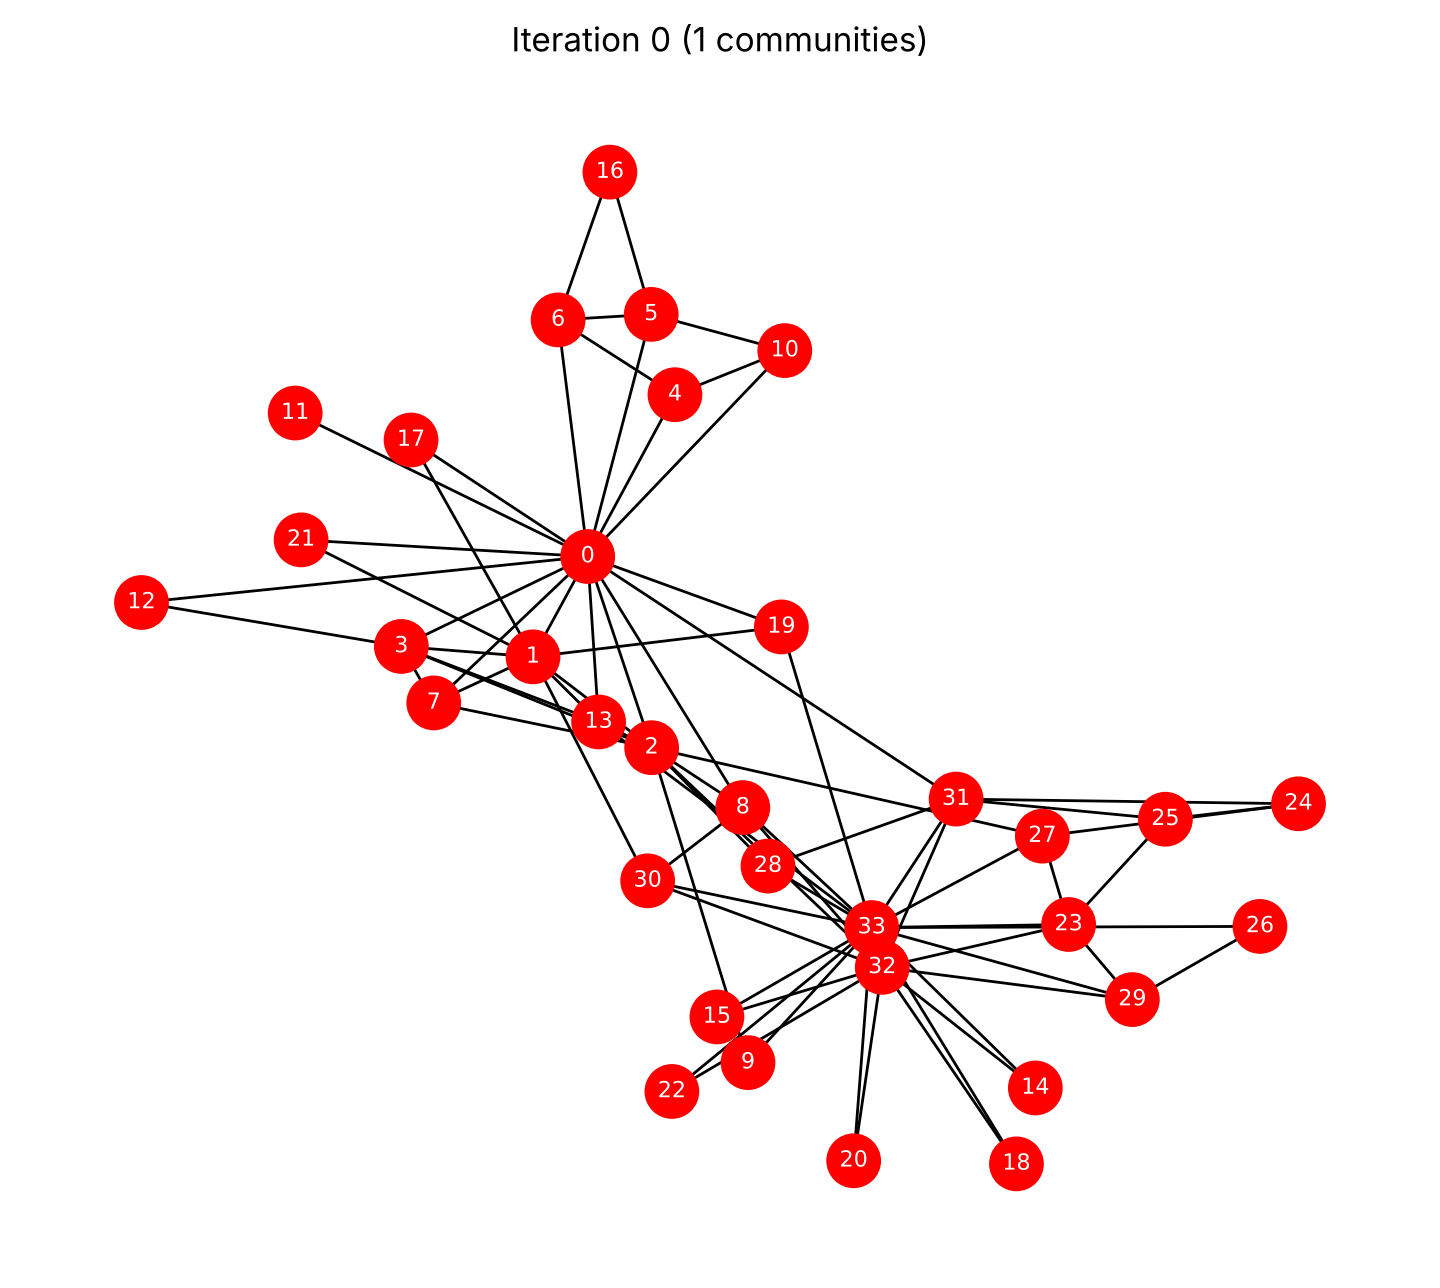

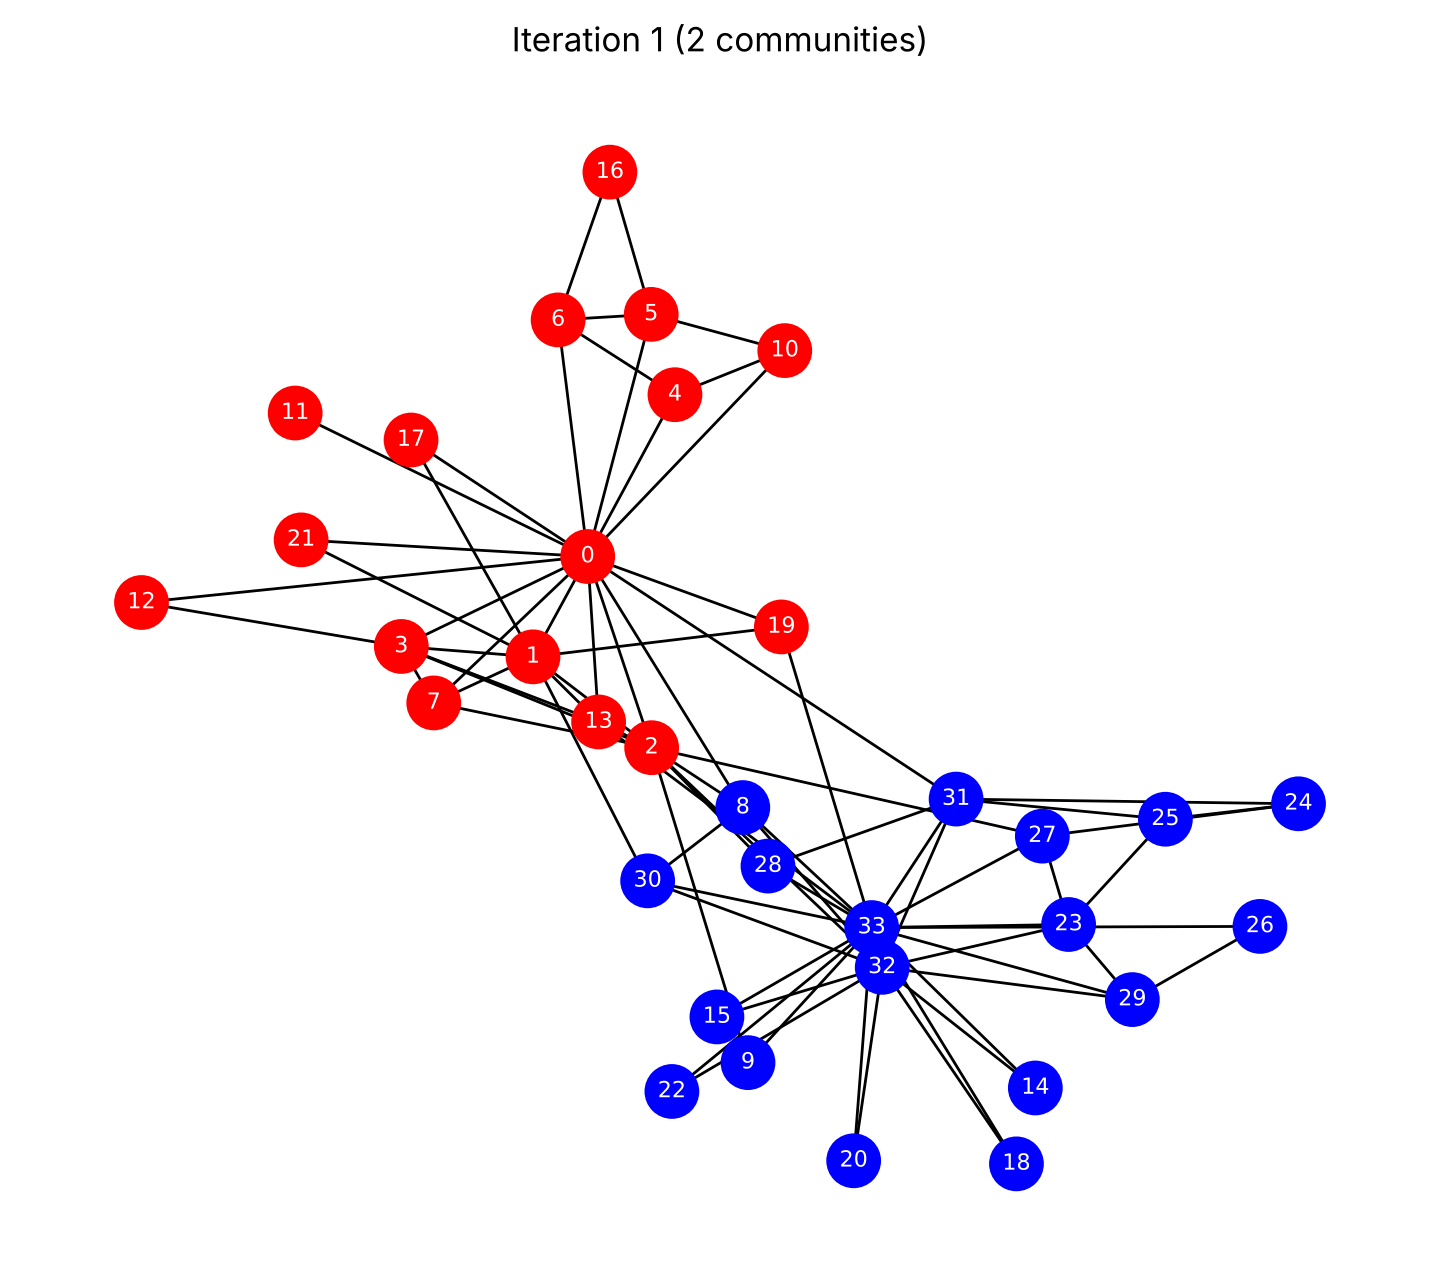

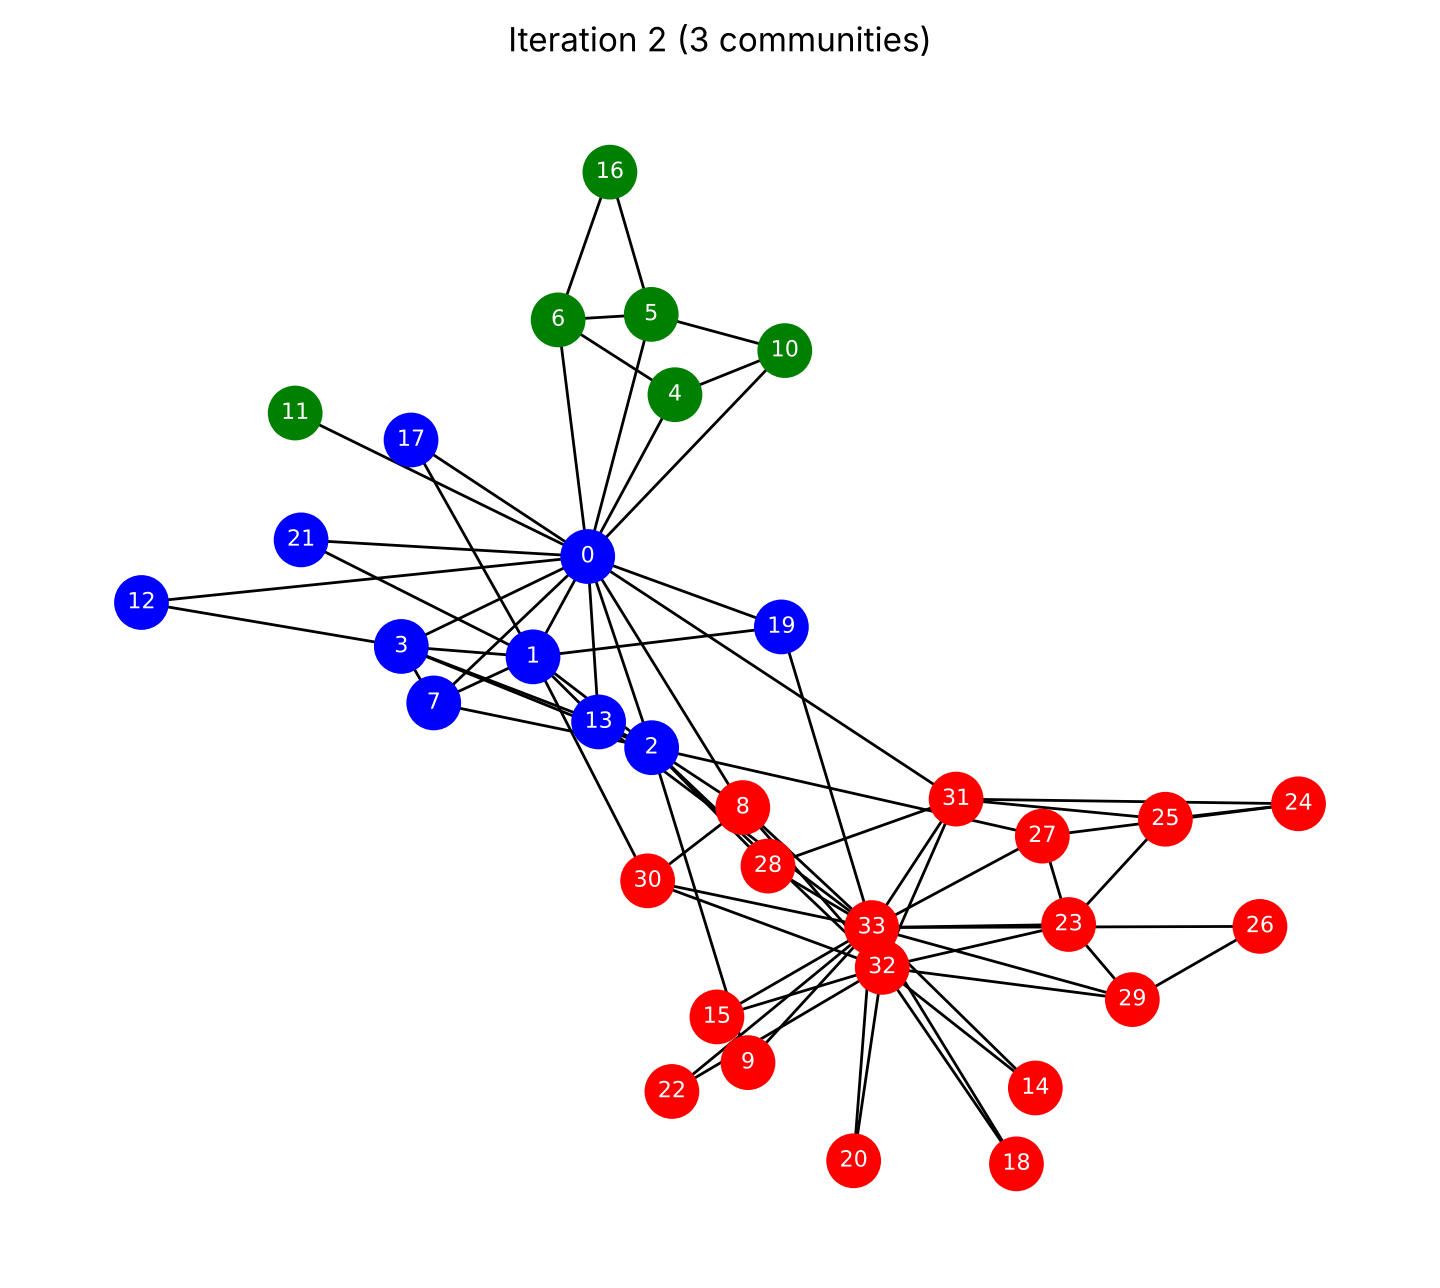

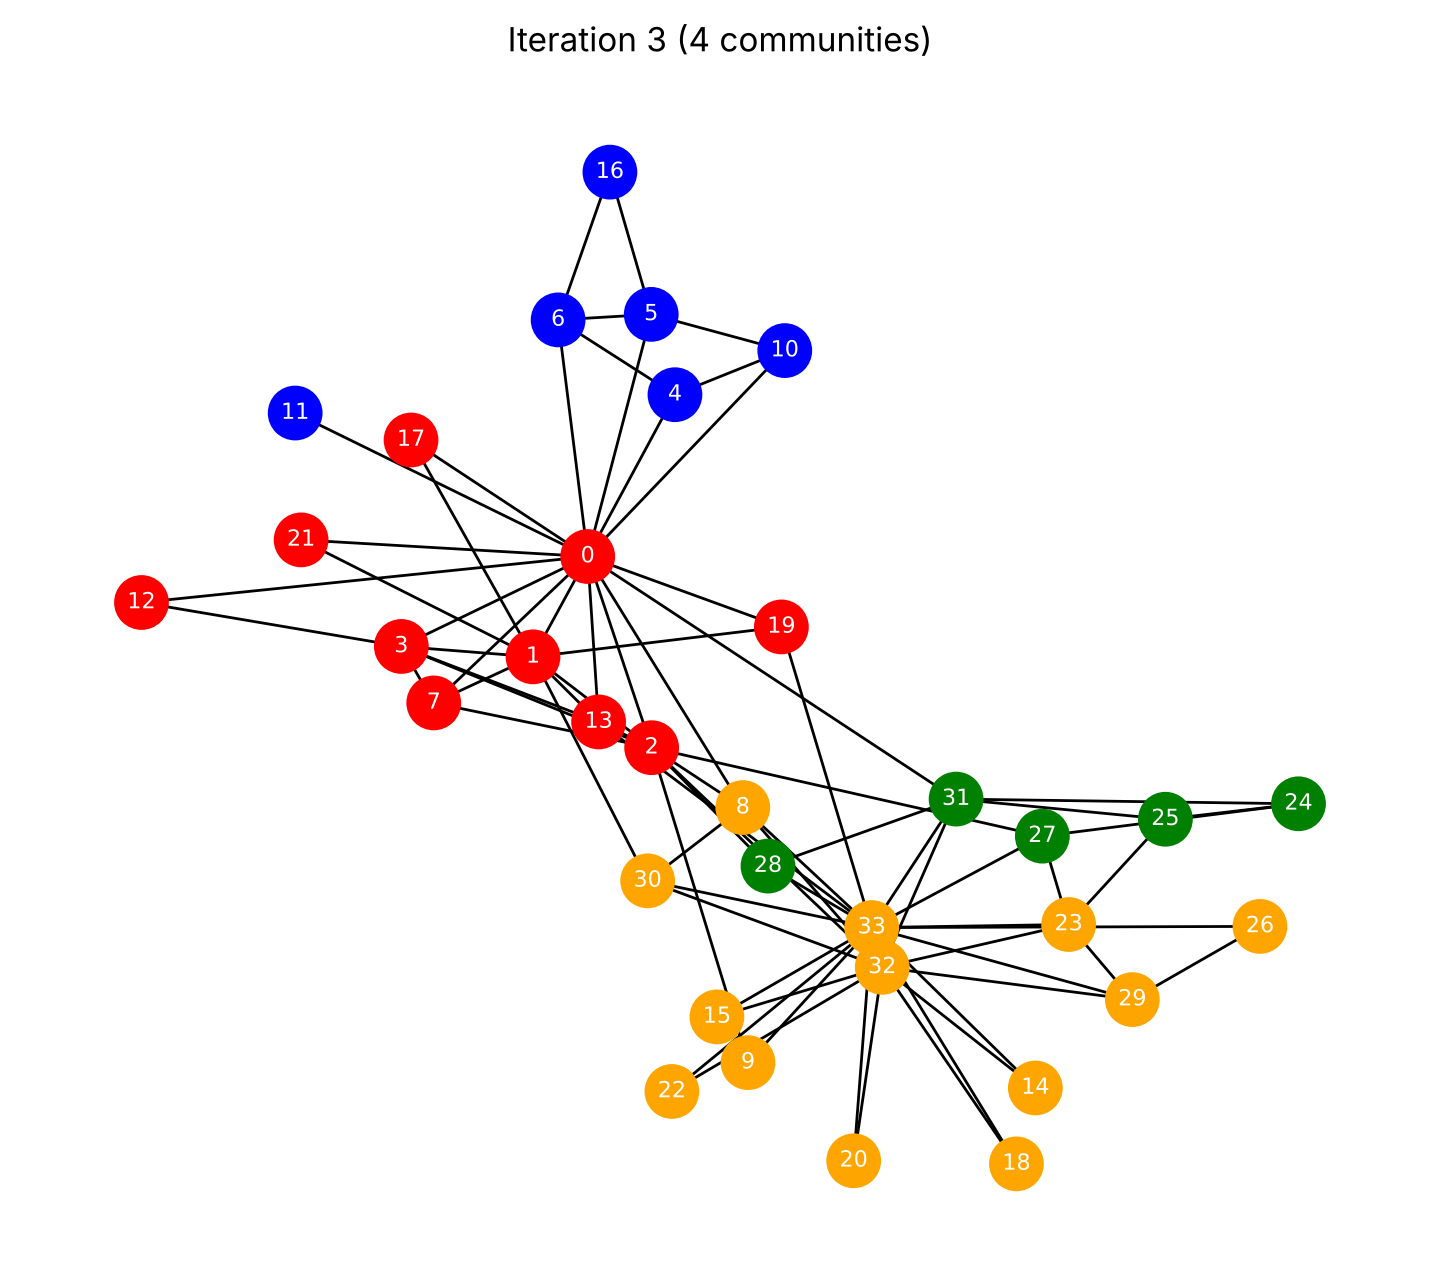

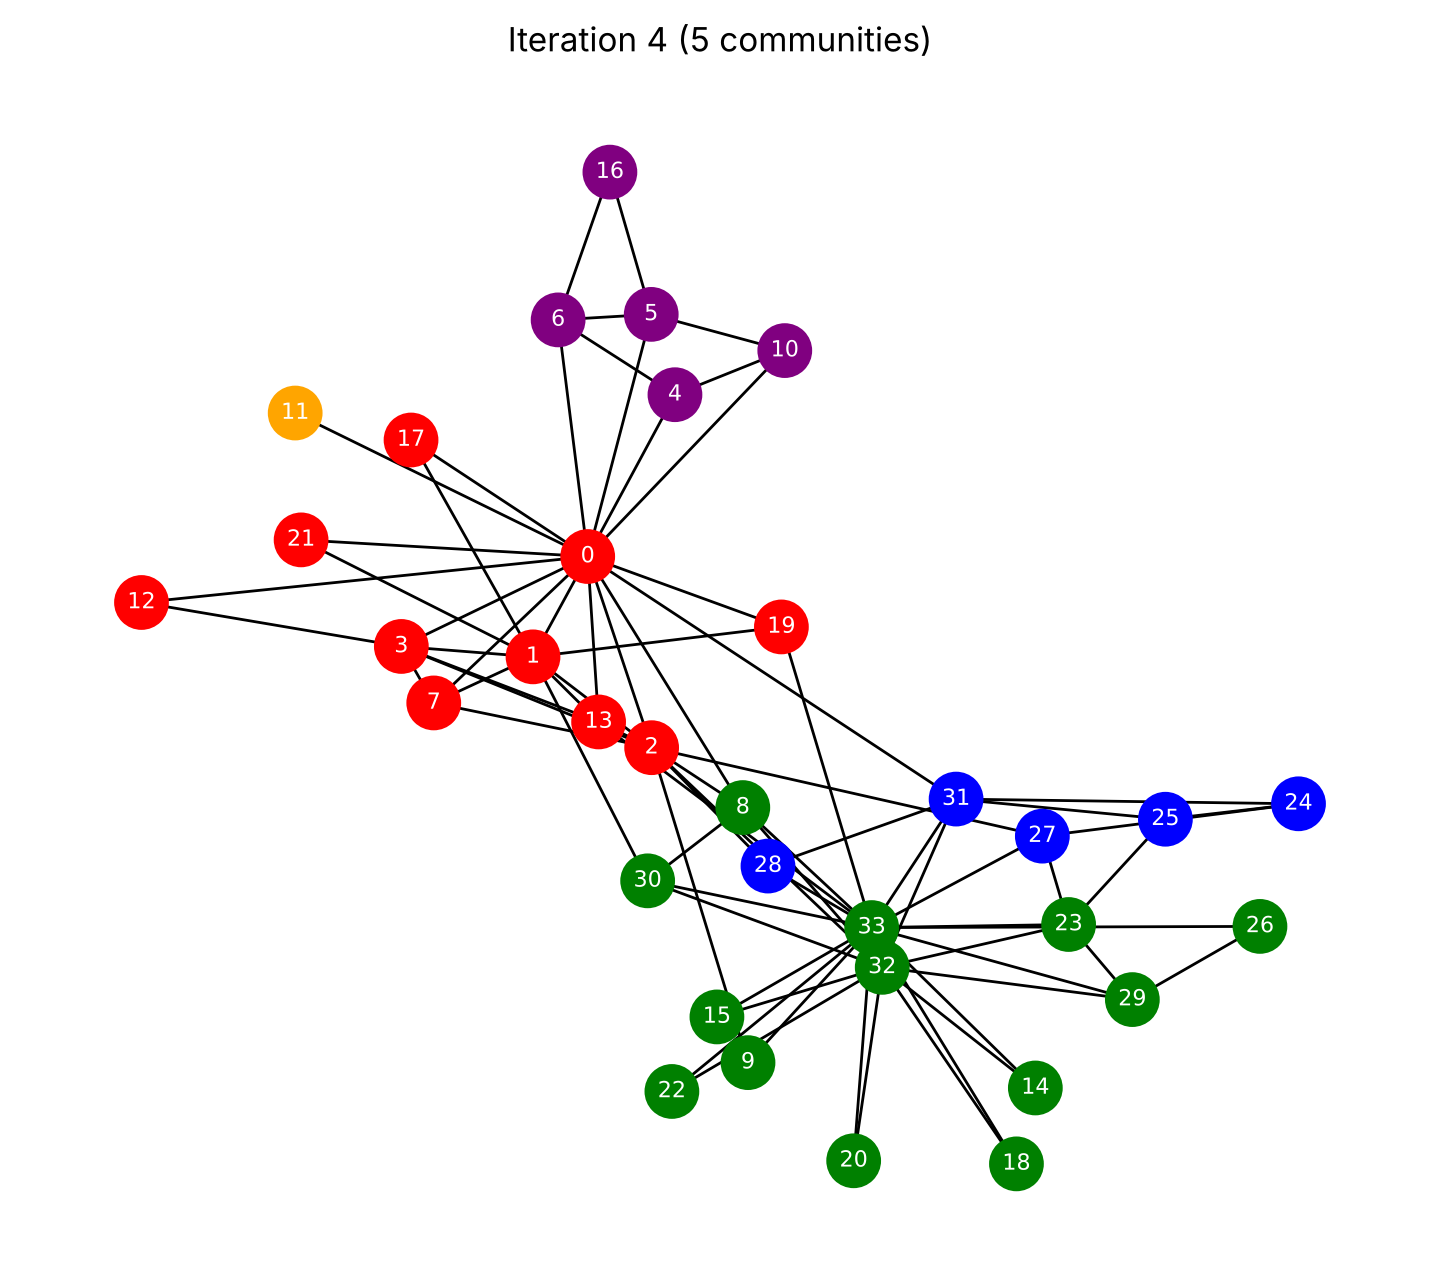

In [10]:
pos = nx.spring_layout(G, seed=42)

colors = ["red", "blue", "green", "orange", "purple", "cyan", "brown", "pink"]

def draw_partition(partition, title):
    color_list = []
    for node in range(n):
        for j in range(len(partition)):
            if node in partition[j]:
                color_list.append(colors[j % len(colors)])
    plt.figure(figsize=(7, 6))
    nx.draw(G, pos, node_color=color_list, with_labels=True, node_size=350, font_size=8, font_color="white")
    plt.title(title)
    plt.show()

for i in range(len(history)):
    draw_partition(history[i], "Iteration " + str(i) + " (" + str(len(history[i])) + " communities)")

## 7. Node metrics after each split

If I computed the metrics on the full graph, they would never change, because splitting does not change the graph. So after each split, I compute each metric inside the community the node belongs to (using the subgraph of that community). Iteration 0 is the full graph.

In [11]:
metrics = {}

for i in range(len(history)):
    deg = {}
    bet = {}
    clo = {}
    clu = {}

    for c in history[i]:
        sub = G.subgraph(c)
        d = nx.degree_centrality(sub)
        b = nx.betweenness_centrality(sub)
        cl = nx.closeness_centrality(sub)
        cc = nx.clustering(sub)
        for node in c:
            deg[node] = d[node]
            bet[node] = b[node]
            clo[node] = cl[node]
            clu[node] = cc[node]

    metrics[i] = {"degree": deg, "betweenness": bet, "closeness": clo, "clustering": clu}

print("iteration 0, node 0:")
for name in metrics[0]:
    print(" ", name, round(metrics[0][name][0], 3))

iteration 0, node 0:
  degree 0.485
  betweenness 0.438
  closeness 0.569
  clustering 0.15


## 8. Plot how the metrics change

There are 34 nodes, so I draw all of them in light grey and highlight the 5 nodes with the highest degree at the start.

top 5 nodes: [33, 0, 32, 2, 1]


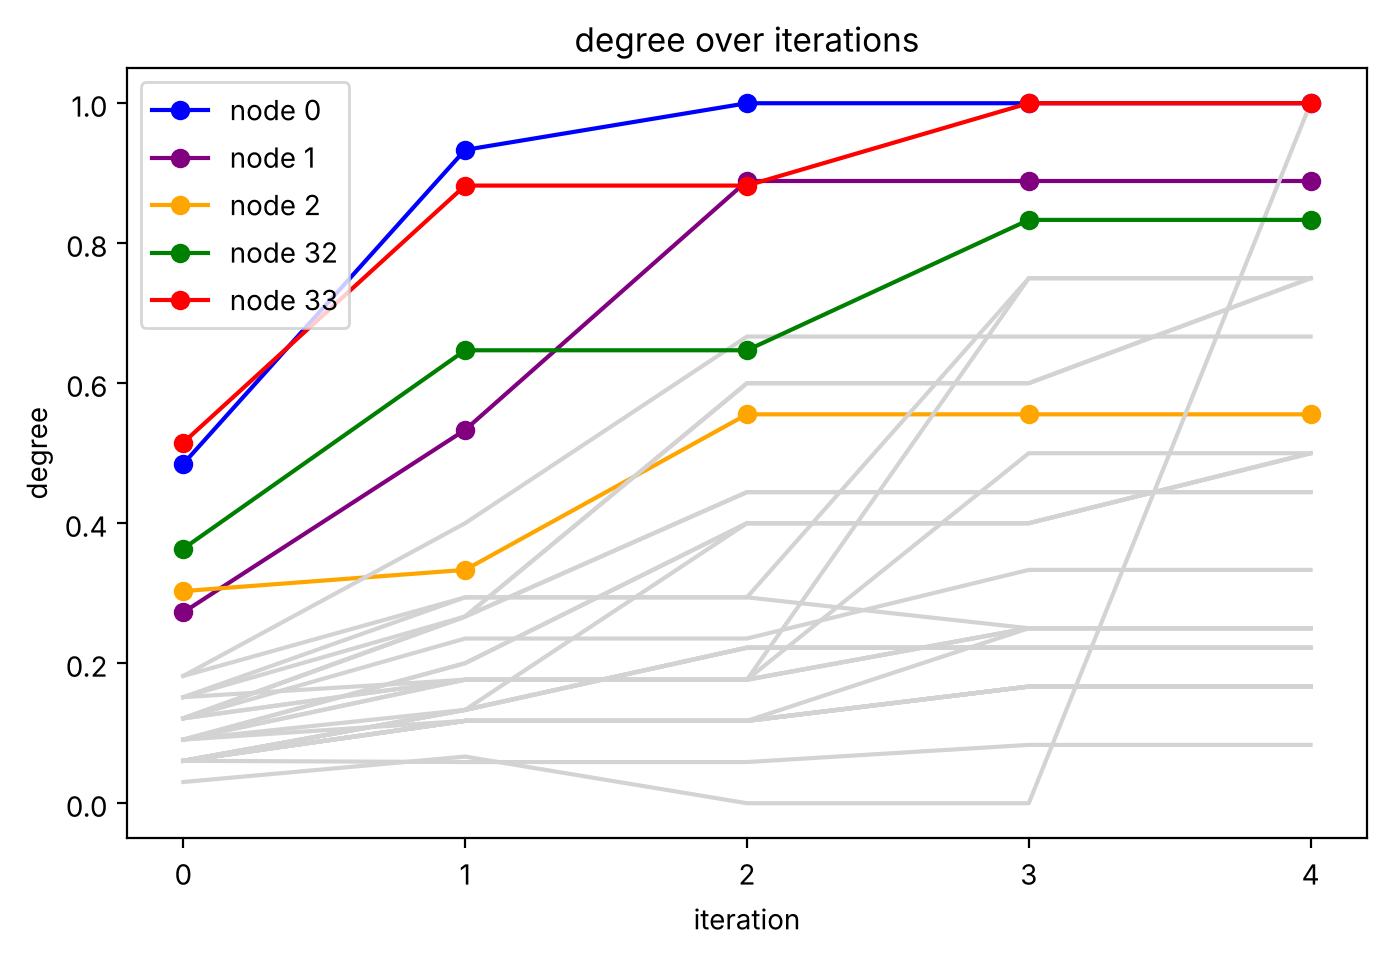

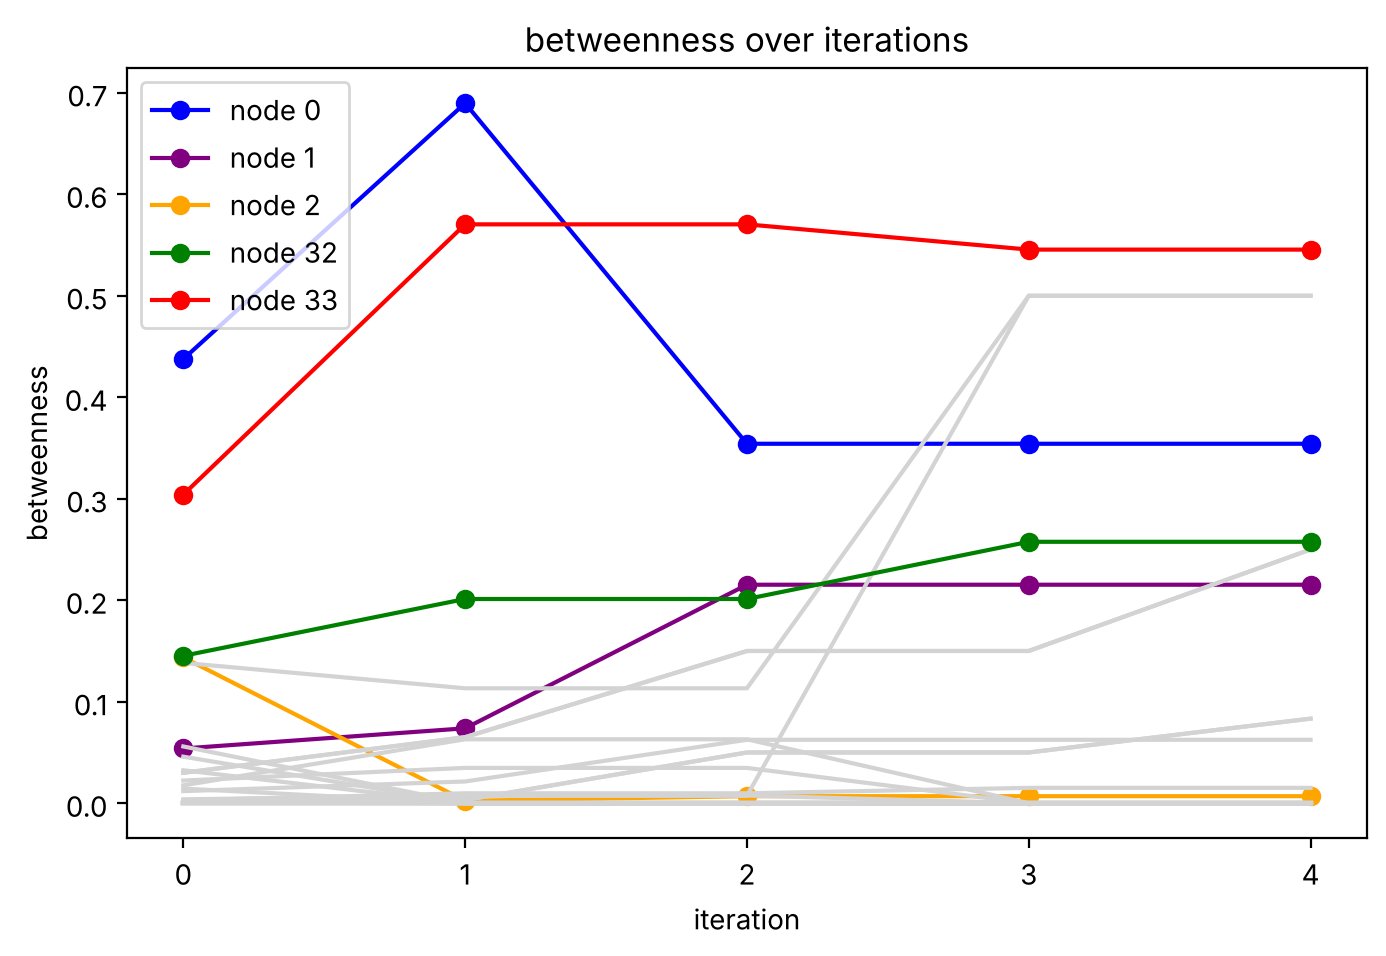

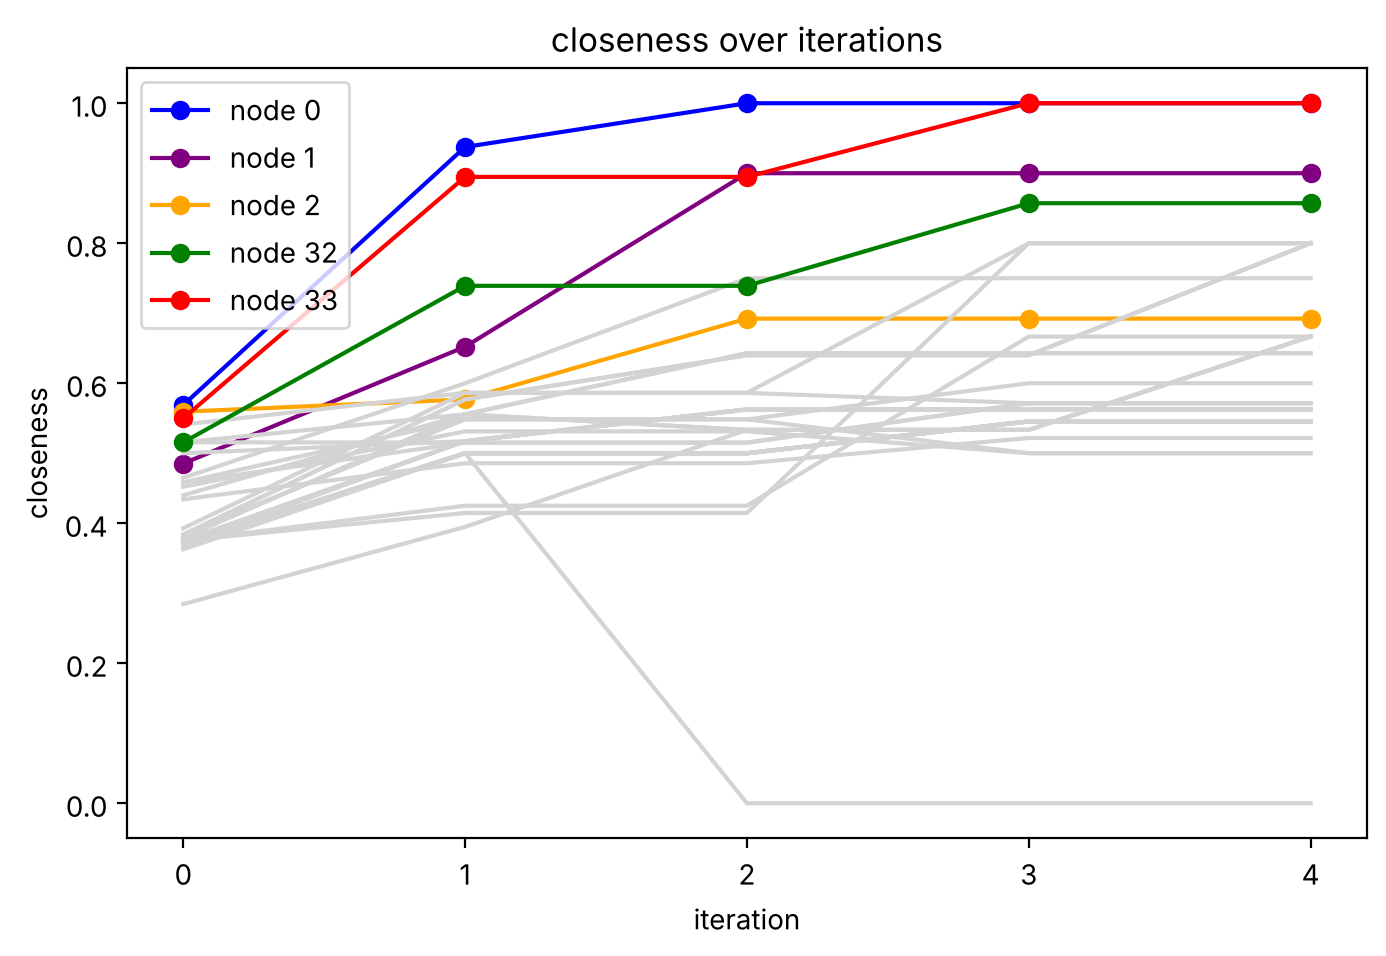

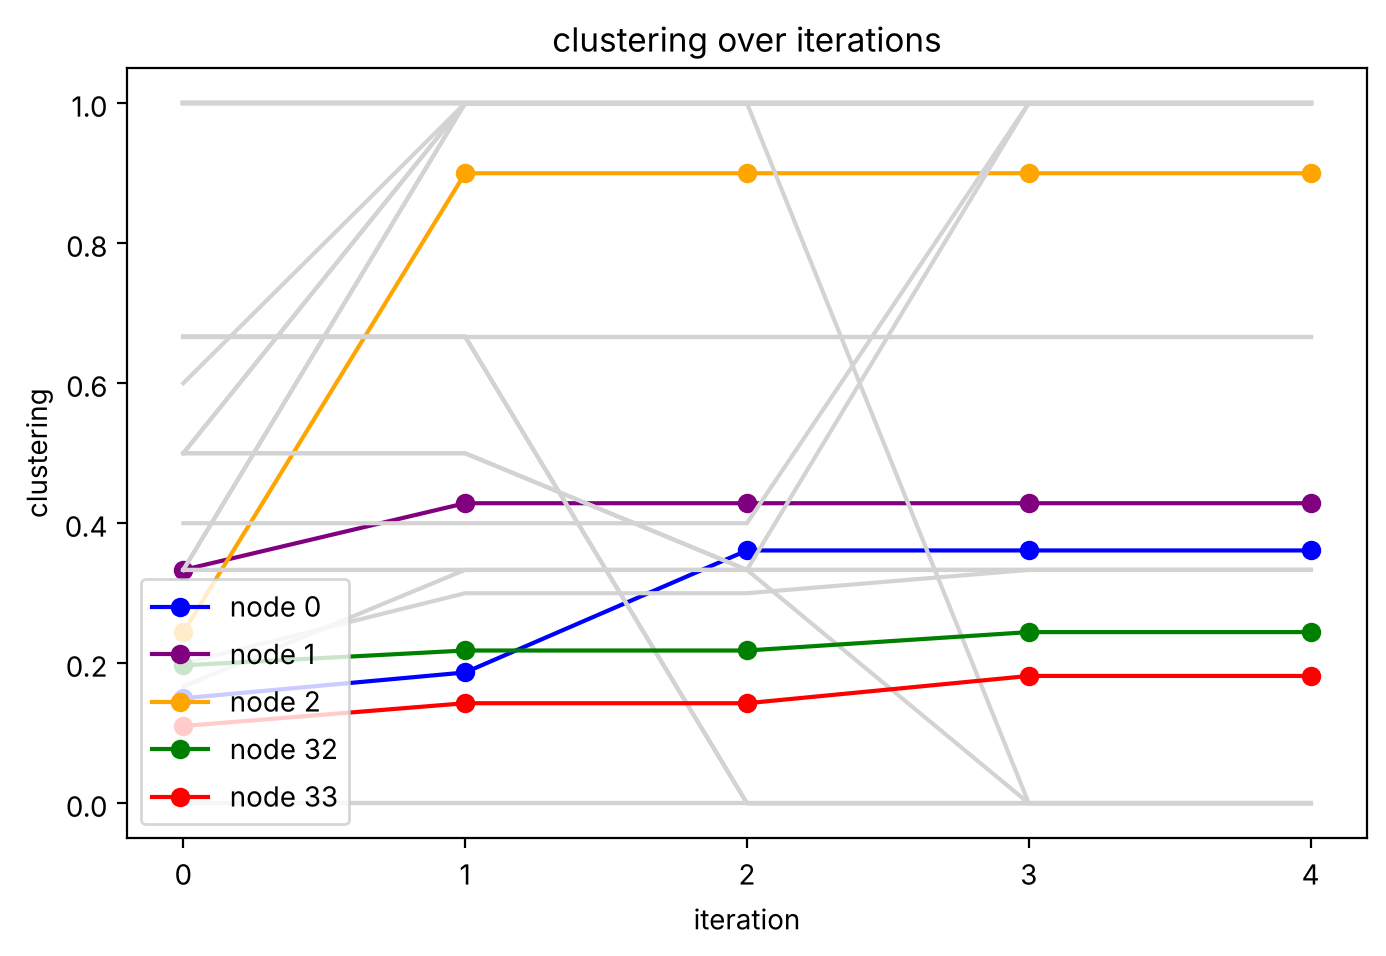

In [12]:
top5 = sorted(metrics[0]["degree"], key=metrics[0]["degree"].get, reverse=True)[:5]
print("top 5 nodes:", top5)

iterations = list(range(len(history)))
highlight_colors = ["red", "blue", "green", "orange", "purple"]

def plot_metric(name):
    plt.figure(figsize=(8, 5))
    for node in range(n):
        values_list = []
        for i in iterations:
            values_list.append(metrics[i][name][node])
        if node in top5:
            plt.plot(iterations, values_list, marker="o", color=highlight_colors[top5.index(node)], label="node " + str(node))
        else:
            plt.plot(iterations, values_list, color="lightgrey")
    plt.title(name + " over iterations")
    plt.xlabel("iteration")
    plt.ylabel(name)
    plt.xticks(iterations)
    plt.legend()
    plt.show()

plot_metric("degree")
plot_metric("betweenness")
plot_metric("closeness")
plot_metric("clustering")

Bar plot of all 34 nodes for the first and last iteration (degree centrality), to see the change for every node.

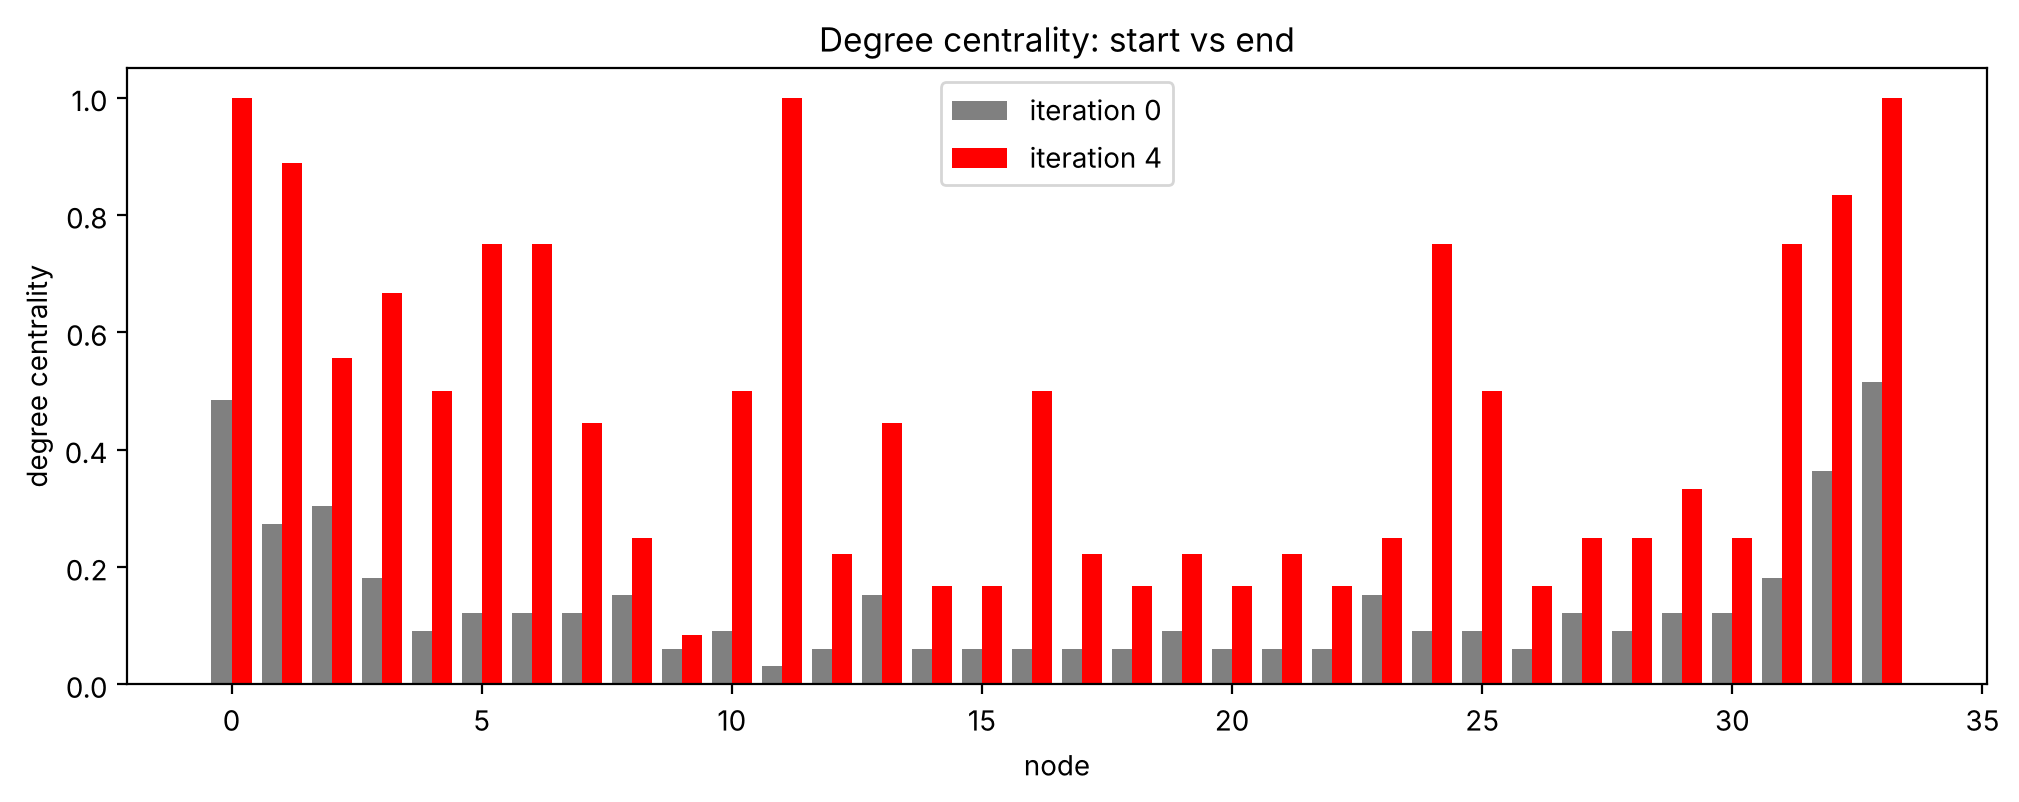

In [13]:
last = len(history) - 1
first_vals = []
last_vals = []
for node in range(n):
    first_vals.append(metrics[0]["degree"][node])
    last_vals.append(metrics[last]["degree"][node])

x = np.arange(n)
plt.figure(figsize=(12, 4))
plt.bar(x - 0.2, first_vals, width=0.4, label="iteration 0", color="grey")
plt.bar(x + 0.2, last_vals, width=0.4, label="iteration " + str(last), color="red")
plt.xlabel("node")
plt.ylabel("degree centrality")
plt.title("Degree centrality: start vs end")
plt.legend()
plt.show()

## 9. Final result

In [14]:
final_Q = modularity_many(B, communities, m)
print("final number of communities:", len(communities))
print("final modularity Q:", round(final_Q, 4))

check = nx.community.modularity(G, communities, weight=None)
print("networkx modularity (just to check):", round(check, 4))

final number of communities: 5
final modularity Q: 0.4094
networkx modularity (just to check): 0.4094


## 10. Discussion
**Which nodes stay central?** Nodes 0 and 33 stay on top the whole time. Node 0 (Mr. Hi) and node 33 (the officer) have the highest degree, betweenness and closeness in the full graph, and they are still the top nodes inside their own communities after the splits. Node 32 and node 1 are also fairly central. Node 2 stays interesting because its clustering is high (about 0.9) in every iteration, so it sits inside a tight group of friends even though it is not a hub.

**How the communities change the metrics.** Because I measure each node inside its own community, the numbers change after every split. Degree and closeness go up for most nodes, since the communities are smaller and every node can reach the others more easily (nodes 0 and 33 reach 1.0 at the end). Betweenness for node 0 drops from about 0.69 to 0.35 after the later splits, because it is no longer the bridge for the whole network, only for its own group. Clustering changes less because it only looks at neighbours, which mostly stay in the same community.

**Other notes.** The first split matches the real club split except for node 8. The later splits kept raising Q (about 0.37 to 0.41 with 5 communities), so the stopping rule worked. A small side note: the handout restricts B to the block for C and does not add Newman's extra diagonal correction, so the groups can keep splitting a bit more than the original paper would. I followed the handout.

## References
Newman, M. E. J. (2006). Modularity and community structure in networks. *PNAS*, 103(23), 8577–8582.

Zachary, W. W. (1977). An information flow model for conflict and fission in small groups. *Journal of Anthropological Research*, 33(4), 452–473.